# 02 — Les variables du modèle

**But :** transformer chaque vente en une série de chiffres, les **variables**, qui décrivent en quoi cette vente est habituelle ou inhabituelle. C'est sur ces variables que le mécanisme 1 (détection d'anomalies) travaillera.

**Principe directeur, issu de l'exploration :** une vente n'est jamais anormale « dans l'absolu ». 200 € est banal en Électronique et énorme en Alimentation ; 15 articles sont normaux pour un professionnel et suspects pour un particulier. Toutes les variables sont donc **relatives** : elles comparent la vente à son contexte.

**Comment lire les écarts.** On travaille en logarithme de base 10 (décision de l'exploration, section 4) :
- un écart de **0** veut dire « comme d'habitude » ;
- un écart de **+1** veut dire « **dix fois plus** que d'habitude », et **+0,3** environ « deux fois plus » ;
- un écart de **-1** veut dire « **dix fois moins** ».

**Règles de méthode :**
- comme l'exploration, ce notebook **ne lit jamais la vérité terrain** ;
- le calcul des variables est écrit **une seule fois**, dans `mechanisms/arrival/features.py`. Ce notebook l'appelle pour l'expliquer, et le mécanisme 1 l'appellera pour détecter : ce qu'on montre est exactement ce qu'utilise le modèle.

**Sommaire**
1. Le périmètre : quelles lignes reçoivent des variables ?
2. L'écart à la catégorie
3. L'écart de prix unitaire
4. L'écart de quantité au segment
5. L'écart à l'habitude du client
6. La rareté de l'heure pour le canal
7. Le délai et l'écart avec l'achat précédent
8. Les variables se répètent-elles ? (corrélations)
9. Synthèse : les variables retenues
10. Un point de vigilance : le risque de circularité

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from viz import ROOT, PALETTE, CHANNEL_ORDER, CHANNEL_COLOR, INK_2, MUTED, HIGHLIGHT, setup, save

sys.path.insert(0, str(ROOT))
from mechanisms.arrival.features import FEATURES, SHRINK_K, build_features, sales_scope

setup()
FOLDER = "variables"

if not (ROOT / "data/ventes/transactions.csv").exists():
    from data_generation.generate import build, write
    write(build(), root=str(ROOT / "data"), summary_path=str(ROOT / "results/metrics/generation_summary.json"))

tx = pd.read_csv(ROOT / "data/ventes/transactions.csv", parse_dates=["date_transaction"])
X = build_features(tx)
print(f"{len(X):,} ventes décrites par {X.shape[1]} variables · valeurs manquantes : {int(X.isna().sum().sum())}".replace(",", " "))

34 309 ventes décrites par 8 variables · valeurs manquantes : 0


## 1. Le périmètre : quelles lignes reçoivent des variables ?

**On regarde** quelles transactions entrent dans le calcul.

In [2]:
scope = sales_scope(tx)
summary = pd.Series({
    "transactions publiées": len(tx),
    "remboursements (traités à part)": int((tx["type_transaction"] == "remboursement").sum()),
    "ventes à montant vide, nul ou négatif (quarantaine directe)": int(((tx["type_transaction"] == "vente") & ~(tx["montant"] > 0)).sum()),
    "ventes qui reçoivent des variables": len(scope),
})
summary.to_frame("lignes")

,lignes
transactions publiées,36364
remboursements (traités à part),1890
"ventes à montant vide, nul ou négatif (quarantaine directe)",165
ventes qui reçoivent des variables,34309


**On conclut et on décide.**
- **Les remboursements sont mis à part**, car leur distribution n'a rien à voir avec celle des ventes (exploration, section 5). Ils auront leur propre traitement.
- **Les ventes à montant vide, nul ou négatif ne reçoivent pas de variables** : elles violent déjà le contrat et partent directement en quarantaine. Inutile de demander à l'IA ce qu'une règle sait déjà.
- Les **34 309 ventes** restantes reçoivent chacune 8 variables.
- Les montants suisses, en francs, sont **convertis en euros** avant le calcul, pour que « 100 » veuille dire la même chose partout.

### Vue d'ensemble : les quatre écarts sur une même échelle

Les quatre premières variables sont des **écarts en logarithme**, donc dans la même unité : on peut les comparer sur un seul graphique. Chaque boîte à moustaches montre la médiane (le trait), la moitié centrale des ventes (la boîte) et les valeurs extrêmes (les points). Les sections 2 à 5 les commentent une par une.

In [3]:
gaps = ["ecart_categorie", "ecart_prix_unitaire", "ecart_quantite_segment", "ecart_habitude_client"]
names = ["Écart à la catégorie", "Écart de prix unitaire", "Écart de quantité au segment", "Écart à l'habitude du client"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([X[g] for g in gaps][::-1], vert=False, widths=0.55, patch_artist=True, whis=1.5,
           medianprops=dict(color=INK_2, lw=2), boxprops=dict(facecolor="#cde2fb", edgecolor=PALETTE[0], lw=1.4),
           whiskerprops=dict(color=PALETTE[0], lw=1.2), capprops=dict(color=PALETTE[0], lw=1.2),
           flierprops=dict(marker="o", ms=2.5, mfc=PALETTE[0], mec="none", alpha=0.25))
ax.set_yticks(range(1, 5), names[::-1])
ax.axvline(0, color=INK_2, lw=1, ls="--")
ax.set_xticks([-2, -1, 0, 1, 2], ["÷ 100", "÷ 10", "comme\nd'habitude", "× 10", "× 100"])
ax.set_title("Figure 7 — Les quatre écarts : médiane, quartiles et valeurs extrêmes")
ax.set_xlabel("écart à la référence (échelle log)"); ax.grid(axis="y", visible=False)
print(save(fig, "07_synthese_ecarts", FOLDER)); plt.show()

X[gaps].describe(percentiles=[0.25, 0.5, 0.75]).loc[["25%", "50%", "75%", "min", "max"]].round(2)

results/figures/variables/07_synthese_ecarts.png


<Figure size 1100x550 with 1 Axes>

,ecart_categorie,ecart_prix_unitaire,ecart_quantite_segment,ecart_habitude_client
25%,-0.24,-0.20,0.00,-0.18
50%,0.00,0.00,0.00,0.00
75%,0.30,0.20,0.05,0.19
min,-1.57,-1.91,-1.18,-1.46
max,2.39,1.63,1.30,1.63


**On conclut, d'un coup d'œil.**
- Les **quatre médianes sont à 0** : par construction, la vente typique est « comme d'habitude » dans son contexte.
- Les boîtes n'ont **pas la même largeur**. L'écart à la catégorie est le plus dispersé, car il mélange le prix et la quantité. Le prix unitaire et l'habitude du client sont plus resserrés. La quantité au segment est très concentrée, parce que presque tout le monde achète la quantité habituelle de son segment.
- **Chaque variable a ses propres valeurs extrêmes**, et ce ne sont pas les mêmes ventes : c'est ce qui rend leur combinaison intéressante.

## 2. L'écart à la catégorie

**Ce que c'est :** le montant de la vente comparé au montant médian de sa catégorie.

**Pourquoi :** l'exploration (section 4, figure 2) a montré que chaque catégorie a son propre niveau de prix, de 30 € pour l'Alimentation à 240 € pour l'Électronique.

**On regarde** sa boîte dans la figure 7 (première ligne) et quelques chiffres.

In [4]:
print(f"Ventes à plus de 10 fois la médiane de leur catégorie : {(X['ecart_categorie'] > 1).sum()}")
print(f"Ventes à moins d'un dixième de la médiane            : {(X['ecart_categorie'] < -1).sum()}")

Ventes à plus de 10 fois la médiane de leur catégorie : 2533
Ventes à moins d'un dixième de la médiane            : 59


**On conclut.**
- La distribution est centrée sur 0 : la plupart des ventes sont proches du prix typique de leur catégorie.
- La queue de droite est longue : **2 533 ventes dépassent dix fois la médiane** de leur catégorie. Ce sont surtout les **commandes de professionnels**, qui achètent beaucoup d'articles d'un coup, donc des montants normaux pour eux.

**On décide.**
- On garde cette variable : elle ramène toutes les catégories à la même échelle.
- Mais elle **ne suffit pas seule** : un gros montant peut s'expliquer par la quantité. D'où les deux variables suivantes, qui séparent le prix par article et la quantité.

## 3. L'écart de prix unitaire

**Ce que c'est :** le prix **par article** (montant ÷ quantité), comparé au prix par article médian de la catégorie.

**Pourquoi :** l'exploration (section 6) a montré un groupe isolé de particuliers achetant 8 à 20 articles, signe probable d'une erreur de saisie de quantité. Si la quantité est fausse mais que le montant est juste, le prix par article devient anormalement bas.

In [5]:
print(f"Prix par article plus de 8 fois inférieur à la médiane (écart < -0,9) : {(X['ecart_prix_unitaire'] < -0.9).sum()}")
print(f"Prix par article plus de 8 fois supérieur (écart > +0,9)             : {(X['ecart_prix_unitaire'] > 0.9).sum()}")

Prix par article plus de 8 fois inférieur à la médiane (écart < -0,9) : 148
Prix par article plus de 8 fois supérieur (écart > +0,9)             : 143


**On conclut.**
- Cette variable est **beaucoup plus resserrée** que la précédente : la quantité n'y joue plus. Les commandes de professionnels, qui gonflaient la queue de l'écart à la catégorie, rentrent dans le rang, puisque leur prix **par article** est normal.
- Il reste des ventes aux deux extrémités : **148 ventes ont un prix par article plus de 8 fois inférieur** à la normale, et 143 plus de 8 fois supérieur.

**On décide.** On garde cette variable : elle est la mieux placée pour repérer une erreur de quantité, ou un article vendu à un prix absurde.

## 4. L'écart de quantité au segment

**Ce que c'est :** la quantité achetée, comparée à la quantité médiane du segment (Particulier, Premium ou Professionnel).

**Pourquoi :** l'exploration (section 6, figure 3) a montré que 15 articles sont normaux pour un professionnel, mais pas pour un particulier.

In [6]:
print(f"Ventes à plus de 6 fois la quantité médiane de leur segment (écart > 0,8) : {(X['ecart_quantite_segment'] > 0.8).sum()}")

Ventes à plus de 6 fois la quantité médiane de leur segment (écart > 0,8) : 107


**On conclut.**
- La variable ne prend que quelques valeurs, car les quantités sont des nombres entiers : 0 pour un article chez un particulier, 0,3 pour deux articles, 0,48 pour trois, etc.
- Grâce au calcul **par segment**, les commandes de professionnels restent près de 0 : ce sont des quantités normales pour eux.
- **107 ventes** dépassent 6 fois la quantité médiane de leur segment. Ce petit groupe isolé correspond à celui repéré à l'exploration.

**On décide.** On garde cette variable, en complément du prix unitaire : une erreur de quantité se voit alors **deux fois**, par une quantité trop forte pour le segment, et par un prix par article trop faible.

## 5. L'écart à l'habitude du client

**Ce que c'est :** le montant comparé à la médiane des achats **de ce client**, multiplié par un **coefficient de confiance** qui dépend du nombre d'achats connus du client.

**Pourquoi ce coefficient ?** Avec un ou deux achats, on ne connaît pas l'« habitude » d'un client : comparer à sa médiane n'a pas de sens. Avec vingt achats, on la connaît bien. Le coefficient vaut **n ÷ (n + 3)**, où n est le nombre d'achats du client. C'est une technique classique de **rétrécissement** (*shrinkage*) : quand on a peu d'informations, on ramène l'écart vers 0, c'est-à-dire « pas d'avis ».

In [7]:
n = np.array([1, 2, 3, 5, 8, 10, 20, 40])
display(pd.DataFrame({"achats connus du client": n, "coefficient de confiance": (n / (n + SHRINK_K)).round(2)}).set_index("achats connus du client").T)

per_client = scope["client_id"].value_counts()
print(f"Achats par client : médiane {per_client.median():.0f} · clients avec moins de 3 achats : {100 * (per_client < 3).mean():.0f} %")

print(f"Ventes à plus de 5 fois l'habitude du client (écart pondéré > 0,7) : {(X['ecart_habitude_client'] > 0.7).sum()}")
print(f"Ventes à plus de 10 fois (écart pondéré > 1)                      : {(X['ecart_habitude_client'] > 1).sum()}")

achats connus du client,1,2,3,5,8,10,20,40
coefficient de confiance,0.25,0.4,0.5,0.62,0.73,0.77,0.87,0.93


Achats par client : médiane 8 · clients avec moins de 3 achats : 11 %
Ventes à plus de 5 fois l'habitude du client (écart pondéré > 0,7) : 1014
Ventes à plus de 10 fois (écart pondéré > 1)                      : 169


**On conclut.**
- Un client typique a **8 achats** dans l'année, ce qui donne un coefficient de confiance de 0,73. Environ **11 % des clients ont moins de 3 achats** : leur écart est fortement ramené vers 0.
- Après pondération, **1 014 ventes** dépassent encore 5 fois l'habitude de leur client, et **169** la dépassent 10 fois.
- Comme l'exploration l'avait montré (section 8), **la variabilité naturelle reste forte** : beaucoup de ces gros achats sont légitimes (une télévision achetée par un client qui achète d'ordinaire des câbles).

**On décide.**
- On garde cette variable : c'est la seule qui compare un client **à lui-même**, et donc la seule capable de repérer un achat banal pour la catégorie mais inhabituel pour ce client.
- On ne lui demande pas de décider seule. Le modèle la combinera avec les autres : un achat dix fois plus cher que d'habitude, **dans une catégorie que le client n'achète jamais, à un prix par article aberrant**, est plus suspect qu'un simple gros achat.

## 6. La rareté de l'heure pour le canal

**Ce que c'est :** à quel point l'heure de la vente est rare **pour ce canal**, calculé à partir de la fréquence observée de cette heure dans ce canal (plus la valeur est grande, plus l'heure est rare).

**Pourquoi :** l'exploration (section 7) a montré des ventes « en magasin » la nuit. On n'écrit **aucune heure d'ouverture en dur** : la variable apprend des données ce qui est fréquent ou rare.

results/figures/variables/08_rarete_heure_canal.png


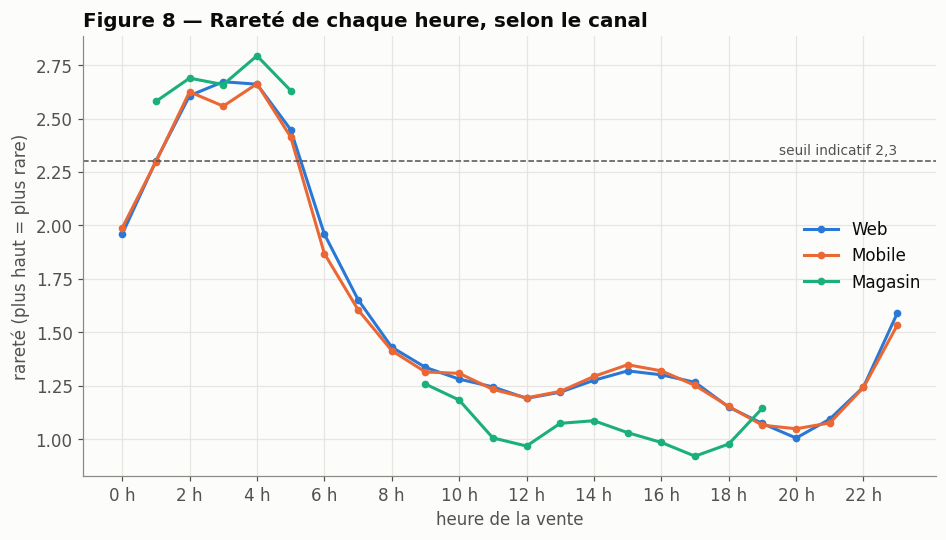

Ventes au-dessus du seuil indicatif de 2,3 : 440


moment,nuit (0 h-5 h)
canal,
Magasin,69
Mobile,109
Web,262


In [8]:
hour = scope["date_transaction"].dt.hour.to_numpy()
canal = scope["canal"].to_numpy()
r = X["rarete_heure_canal"].to_numpy()

fig, ax = plt.subplots()
for ch in CHANNEL_ORDER:
    mask = canal == ch
    by_hour = pd.Series(r[mask]).groupby(hour[mask]).first().reindex(range(24))
    ax.plot(by_hour.index, by_hour.values, marker="o", ms=4, color=CHANNEL_COLOR[ch], label=ch)
ax.axhline(2.3, color=INK_2, ls="--", lw=1)
ax.text(23, 2.33, "seuil indicatif 2,3", ha="right", color=INK_2, fontsize=9)
ax.set_xticks(range(0, 24, 2), [f"{h} h" for h in range(0, 24, 2)])
ax.set_title("Figure 8 — Rareté de chaque heure, selon le canal")
ax.set_xlabel("heure de la vente"); ax.set_ylabel("rareté (plus haut = plus rare)")
ax.legend(loc="center right")
print(save(fig, "08_rarete_heure_canal", FOLDER)); plt.show()

high = pd.crosstab(pd.Series(canal[r > 2.3], name="canal"), pd.Series(np.where(hour[r > 2.3] < 6, "nuit (0 h-5 h)", "autre"), name="moment"))
print(f"Ventes au-dessus du seuil indicatif de 2,3 : {(r > 2.3).sum()}")
display(high)

**On conclut.**
- En ligne (Web, Mobile), la nuit est **rare mais normale** : quelques personnes achètent à 3 h du matin.
- En magasin, la nuit devrait être **impossible**. Pourtant, la variable donne à peu près **la même rareté** à une vente en magasin à 3 h qu'à un achat en ligne à 3 h, parce que les ventes de nuit en magasin, bien que fautives, sont aussi nombreuses dans les données que les achats en ligne de nuit.
- **Sur les 440 ventes** au-dessus du seuil indicatif, toutes la nuit, **371 sont des achats en ligne**, parfaitement légitimes, et **69 sont des ventes en magasin**, impossibles. La variable les met dans le même sac.

**On décide.**
- **La statistique ne sait pas distinguer « rare » d'« impossible ».** Elle n'apprend que ce qu'elle observe, y compris les erreurs. C'est la **règle du contrat 1.1** (« une vente en magasin a lieu entre 9 h et 20 h ») qui est le bon outil ici.
- On garde quand même la variable, avec un rôle modeste : elle peut repérer d'autres heures anormales qu'on n'a pas imaginées.
- **Leçon à retenir pour le mémoire :** quand une connaissance métier est **certaine** (les horaires d'ouverture), une règle vaut mieux qu'un modèle. L'IA est utile là où la règle ne peut pas être écrite.

## 7. Le délai et l'écart avec l'achat précédent

**Ce que c'est :** pour chaque vente, on cherche l'achat précédent **du même client dans la même catégorie**, et on calcule deux variables :
- le **délai** entre les deux achats (en logarithme des minutes) ;
- l'**écart de montant** entre les deux (en logarithme).

**Pourquoi :** l'exploration (section 9) a montré des doublons exacts (délai nul) et des quasi-doublons (quelques minutes, quelques centimes).

**Pour un premier achat**, sans achat précédent, on fait comme si le précédent datait d'un an, avec un écart de « dix fois » : la vente ne ressemble donc à aucun doublon.

results/figures/variables/09_delai_et_ecart_precedent.png


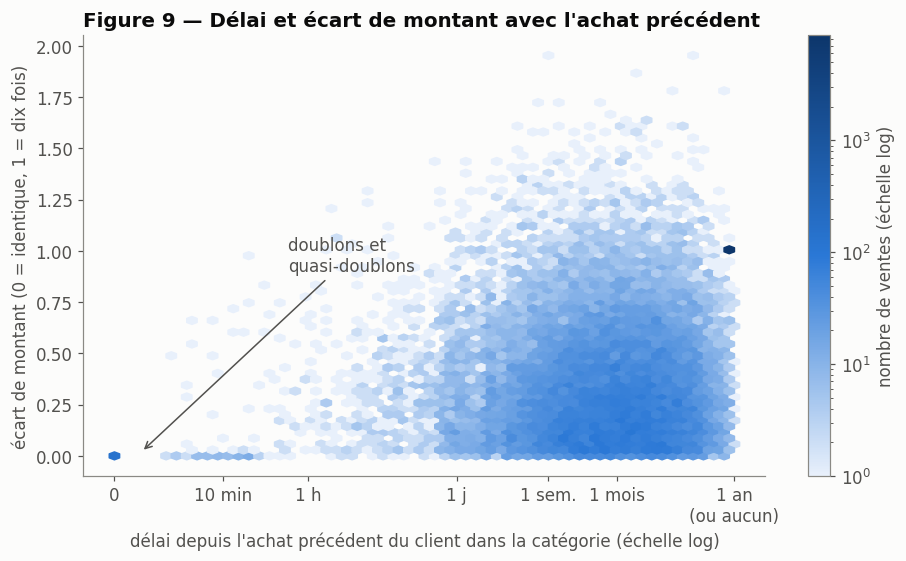

Moins de 30 minutes ET moins de 5 % d'écart de montant : 204 ventes, dont 137 avec un délai nul
Premiers achats (aucun achat précédent dans la catégorie) : 8691


In [9]:
fig, ax = plt.subplots()
hb = ax.hexbin(X["log_delai_precedent"], X["ecart_montant_precedent"], gridsize=60, bins="log",
               cmap=LinearSegmentedColormap.from_list("bleu", ["#e8f0fb", "#2a78d6", "#0d366b"]), mincnt=1)
fig.colorbar(hb, ax=ax, label="nombre de ventes (échelle log)")
ax.set_xticks([0, 1, np.log10(61), np.log10(1441), np.log10(10081), np.log10(43201), np.log10(525601)],
              ["0", "10 min", "1 h", "1 j", "1 sem.", "1 mois", "1 an\n(ou aucun)"])
ax.annotate("doublons et\nquasi-doublons", (0.25, 0.02), xytext=(1.6, 0.9), color=INK_2,
            arrowprops=dict(arrowstyle="->", color=INK_2))
ax.set_title("Figure 9 — Délai et écart de montant avec l'achat précédent")
ax.set_xlabel("délai depuis l'achat précédent du client dans la catégorie (échelle log)")
ax.set_ylabel("écart de montant (0 = identique, 1 = dix fois)")
ax.grid(False)
print(save(fig, "09_delai_et_ecart_precedent", FOLDER)); plt.show()

near = (X["log_delai_precedent"] < np.log10(31)) & (X["ecart_montant_precedent"] < np.log10(1.05))
print(f"Moins de 30 minutes ET moins de 5 % d'écart de montant : {near.sum()} ventes, dont {(X['log_delai_precedent'] == 0).sum()} avec un délai nul")
print(f"Premiers achats (aucun achat précédent dans la catégorie) : {(X['log_delai_precedent'] == np.log10(1 + 525_600)).sum()}")

**On conclut.**
- L'immense majorité des ventes forme un nuage de délais entre quelques jours et quelques mois, avec des écarts de montant variés.
- Une petite tache se détache **en bas à gauche** : **204 ventes** arrivent moins de 30 minutes après un achat presque identique (moins de 5 % d'écart). Parmi elles, **137 ont un délai nul**, ce sont les doublons exacts déjà vus.
- Le point foncé isolé à droite (« 1 an ou aucun », écart de 1) regroupe les **8 691 premiers achats** dans une catégorie, placés là par convention.
- Les deux variables sont **liées** (corrélation de 0,56, section suivante) : c'est attendu, puisque c'est **leur combinaison** qui signale un doublon.

**On décide.** On garde les deux variables ensemble. Le modèle pourra repérer la tache en bas à gauche **sans qu'on fixe de seuil à la main** (30 minutes ou 5 %), et les doublons exacts restent attrapés en plus par la règle du contrat.

## 8. Les variables se répètent-elles ? (corrélations)

**On regarde** la corrélation de Spearman entre chaque paire de variables. Elle va de -1 à +1 : proche de **±1**, les deux variables disent presque la même chose ; proche de **0**, elles apportent des informations différentes.

results/figures/variables/10_correlations.png


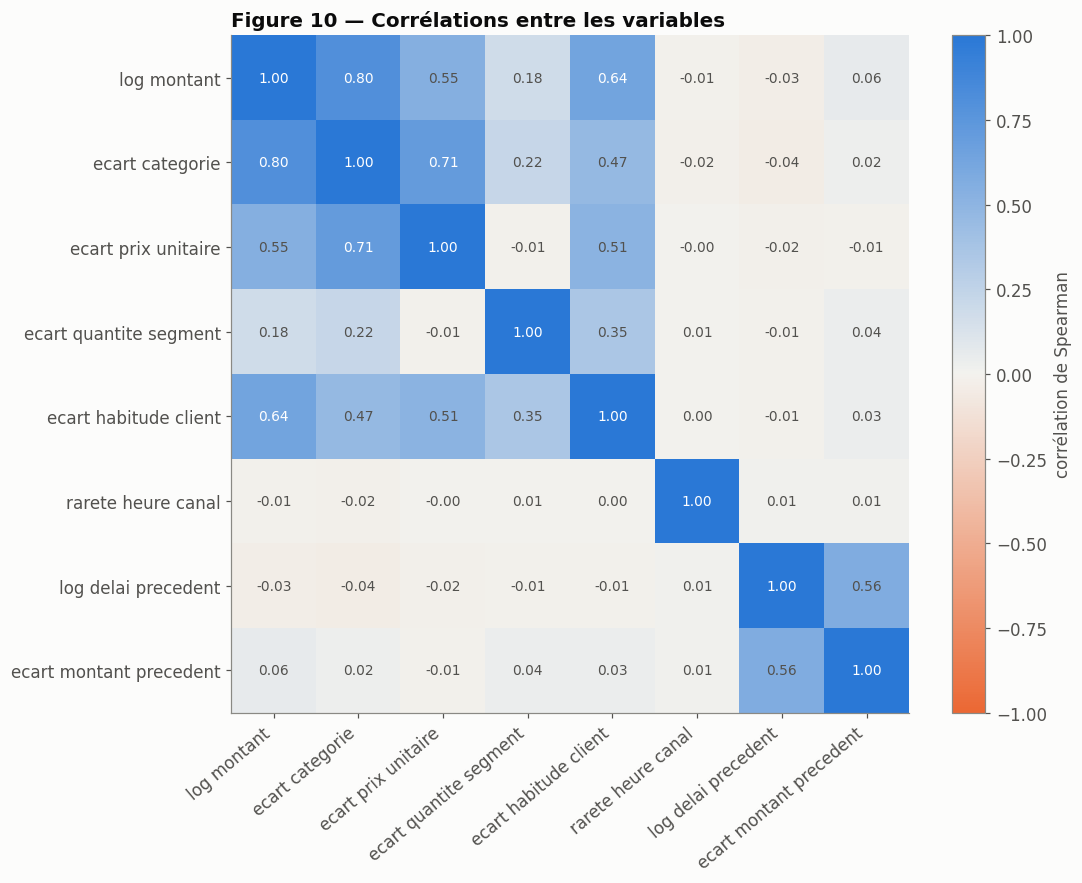

Paires les plus corrélées :
log_montant          ecart_categorie            0.80
ecart_categorie      ecart_prix_unitaire        0.71
log_montant          ecart_habitude_client      0.64
log_delai_precedent  ecart_montant_precedent    0.56
log_montant          ecart_prix_unitaire        0.55


In [10]:
corr = X.corr(method="spearman")
labels = [c.replace("_", " ") for c in corr.columns]
cmap = LinearSegmentedColormap.from_list("divergente", ["#eb6834", "#f3f2ee", "#2a78d6"])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right"); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else INK_2)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="corrélation de Spearman")
ax.set_title("Figure 10 — Corrélations entre les variables")
print(save(fig, "10_correlations", FOLDER)); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("Paires les plus corrélées :"); print(pairs.head(5).round(2).to_string())

**On conclut.**
- **Le logarithme du montant et l'écart à la catégorie sont très corrélés (0,80)** : ils disent presque la même chose, l'écart étant simplement le montant « recentré » sur sa catégorie.
- L'écart à la catégorie et l'écart de prix unitaire sont assez corrélés (0,71), mais **pas redondants** : ils divergent justement quand la quantité est grande, ce qui est l'information qu'on cherche.
- Le délai et l'écart avec l'achat précédent sont liés (0,56), ce qui est attendu (section 7).
- La rareté de l'heure n'est corrélée à rien : elle apporte une information à part.

**On décide.**
- **On retire le logarithme du montant brut du modèle.** Il double l'information de l'écart à la catégorie, et l'exploration a conclu qu'il fallait juger un montant **relativement** à sa catégorie. Le garder reviendrait à donner deux fois plus de poids aux gros montants, et donc à signaler surtout les professionnels.
- On garde les **sept autres** variables.

## 9. Synthèse : les variables retenues

| Variable | Ce qu'elle mesure | Décision de l'exploration | Retenue ? |
|---|---|---|---|
| `log_montant` | Montant en euros, en logarithme | Section 4 : passer au logarithme | **Non**, redondante avec l'écart à la catégorie (0,80). Gardée pour la lecture des résultats. |
| `ecart_categorie` | Montant comparé à la médiane de la catégorie | Section 4 : comparer à la catégorie | Oui |
| `ecart_prix_unitaire` | Prix par article comparé à la catégorie | Section 6 : erreur de quantité | Oui |
| `ecart_quantite_segment` | Quantité comparée au segment | Section 6 : quantités selon le segment | Oui |
| `ecart_habitude_client` | Montant comparé à l'habitude du client, pondéré | Section 8 : habitudes des clients | Oui |
| `rarete_heure_canal` | Rareté de l'heure pour le canal | Section 7 : heures et canaux | Oui, rôle modeste (la règle du contrat 1.1 fait mieux) |
| `log_delai_precedent` | Délai depuis l'achat précédent | Section 9 : doublons | Oui, avec la suivante |
| `ecart_montant_precedent` | Écart de montant avec l'achat précédent | Section 9 : doublons | Oui, avec la précédente |

**Pourquoi on n'a pas mis la catégorie, le pays ou le segment directement dans le modèle ?** Parce que les variables relatives les intègrent déjà : chaque écart est calculé **par** catégorie ou **par** segment. Ajouter ces colonnes en plus multiplierait les dimensions sans apporter d'information nouvelle. C'est l'approche **la plus simple qui reste fidèle à l'exploration**.

In [11]:
MODEL_FEATURES = [f for f in FEATURES if f != "log_montant"]
print(f"{len(MODEL_FEATURES)} variables retenues pour le modèle :")
for f in MODEL_FEATURES:
    print(f"  - {f:<24} {FEATURES[f]}")

7 variables retenues pour le modèle :
  - ecart_categorie          Montant comparé à la médiane de sa catégorie (section 4)
  - ecart_prix_unitaire      Prix par article comparé à la médiane de la catégorie (section 6)
  - ecart_quantite_segment   Quantité comparée à la médiane du segment (section 6)
  - ecart_habitude_client    Montant comparé à l'habitude du client, pondéré par le nombre d'achats (section 8)
  - rarete_heure_canal       Rareté de l'heure d'achat pour ce canal (section 7)
  - log_delai_precedent      Délai depuis l'achat précédent du client dans la catégorie (section 9)
  - ecart_montant_precedent  Écart de montant avec cet achat précédent (section 9)


## 10. Un point de vigilance : le risque de circularité

Il faut le dire clairement, car un jury technique le remarquera : **la même personne a conçu le générateur de données et les variables**. Même si les variables ont été décidées à partir de l'exploration, sans regarder les étiquettes, leur auteur savait quelles familles d'anomalies avaient été injectées. Il y a donc un risque que les variables soient « taillées sur mesure » pour ces anomalies, et que les résultats du modèle soient **trop optimistes**.

C'était déjà une faiblesse de la version 2 du projet.

**Ce qui limite ce risque :**
1. chaque variable est justifiée par une **observation de l'exploration**, faite sans les étiquettes et documentée dans le notebook 01 ;
2. la **référence « expert »** disposera exactement de la même connaissance que l'IA, ce qui rend la comparaison équitable ;
3. **une parade proposée** : évaluer aussi le système sur une **famille d'anomalies « inconnue »**, ajoutée **après** la conception des variables, et pour laquelle aucune variable n'a été pensée. Si le modèle en attrape une partie, c'est la preuve qu'il généralise au-delà de ce qu'on lui a appris à chercher. Si ce n'est pas le cas, on le dira.